In [27]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')


Dependencies OK.


In [28]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment


In [29]:
# ──  Load ────────────────────────────────────────────────────────────────
df_raw = pd.read_excel('../mito/AID_720635_cleaned.xlsx',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())


Raw rows : 8,099
PUBCHEM_ACTIVITY_OUTCOME
Inconclusive    3474
Inactive        3213
Active          1412
Name: count, dtype: int64
count    8099.000000
mean       15.672429
std        23.805444
min         0.000000
25%         0.000000
50%        10.000000
75%        10.000000
max        99.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [30]:
# ──   SMILES + deduplication ──────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi)) #converts to mol object, returns None if invalid
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')


[08:20:16] WARNING: not removing hydrogen atom without neighbors


After parse : 8,099  (removed 0 invalid SMILES)
After dedup : 8,099


[08:20:17] WARNING: not removing hydrogen atom without neighbors
[08:20:17] WARNING: not removing hydrogen atom without neighbors


Removed 3,474 inconclusive
Active   (1): 1,412
Inactive (0): 3,213
Ratio       : 2.3:1


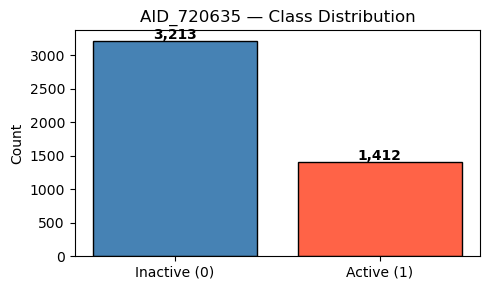

In [31]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_720635 — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png',dpi=150); plt.show()


---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN


In [32]:
# ── 5. Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')


[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerator
[08:20:17] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (4625, 2048)
FP density         : 0.0146


In [33]:
# ──  Rich Atom Features (14-dim) & Bond Features (6-dim) — for GNN ─────────
#
#  14 atom features 
#    Atomic num one-hot (C,N,O,S,F,P,Cl,Br,I,other=10),
#    degree (0-5), formal charge, hybridization one-hot (SP/SP2/SP3/other=4),
#    is_aromatic, is_in_ring, total_Hs (0-4), normalized mass
#
#  6 bond features:
#    bond type one-hot (single/double/triple/aromatic=4),
#    is_conjugated, is_in_ring
#
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass   # 'other' → all zeros
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5) #no of bonds this atom has
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge() #chareg positve or nehative or zero
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

# Test dimensions
from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')


Atom feature dim : 27
Bond feature dim : 6


In [34]:
# ── 7. Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    # Atom features
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    # Bond features + bidirectional edges
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')


[08:20:18] WARNING: not removing hydrogen atom without neighbors


Graphs built: 4,625
Example: Data(x=[13, 27], edge_index=[2, 26], edge_attr=[26, 6], y=[1])


[08:20:19] WARNING: not removing hydrogen atom without neighbors
[08:20:19] WARNING: not removing hydrogen atom without neighbors


---
## Step 3 — 80/20/20 Split + Downsampling


In [35]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

# Parallel split for graph data (using same indices)
idx_all   = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={( y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')


Pool : 3,700  (act=1130, ina=2570)
Test : 925  (act=282, ina=643)


In [36]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test = df.iloc[idx_test].reset_index(drop=True).copy()
df_test['label'] = y_test

print(f'Test set size : {len(df_test):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds × ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  Active   (1): {(y_test == 1).sum():,}')
print(f'  Inactive (0): {(y_test == 0).sum():,}')

print(f'\n── First 10 test set compounds ──')
display(df_test[['PUBCHEM_CID', 'csmi', 'PUBCHEM_ACTIVITY_SCORE', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:20])


Test set size : 925 compounds
X_test shape  : (925, 2048)   (compounds × ECFP4 bits)
y_test shape  : (925,)

Class distribution:
  Active   (1): 282
  Inactive (0): 643

── First 10 test set compounds ──


,PUBCHEM_CID,csmi,PUBCHEM_ACTIVITY_SCORE,label
0,16036578,O=C(NS(=O)(=O)/C=C/c1cccs1)c1ccc(F)cc1Br,41,1
1,13849,CCCCCCCCCCCCCCC(=O)O,0,0
2,2734247,CCCCCCn1cc[n+](C)c1.O=S(=O)([O-])C(F)(F)F,42,1
3,38764,CCCCCCc1ccc(-c2ccc(C#N)cc2)cc1,40,1
4,91692,O=C(Nc1ccccc1)N(Cc1ccc(Cl)cc1)C1CCCC1,82,1
5,2197,COc1ccc(C2C(=O)c3ccccc3C2=O)cc1,0,0
6,92729,Cc1c(O)cc2c(c1C)O[C@](C)(CCC[C@H](C)CCC[C@H](C...,0,0
7,2735045,CCOC(=S)[S-].[K+],0,0
8,5281116,CCCCCCCC/C=C\CCCCCCCCCCCC(=O)O,0,0
9,12120,CCOc1cccc(N)c1,0,0



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[1 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]


In [37]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val  = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')


Train-raw: 2,960  (act=904, ina=2056)
Val      : 740  (act=226,  ina=514)


In [38]:
# ──  Downsampling on TRAIN ONLY ──────────────────────────────
act_idx_tr  = np.where(y_tr_raw == 1)[0]
ina_idx_tr  = np.where(y_tr_raw == 0)[0]
n_act_tr    = len(act_idx_tr)

rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr, replace=False)

train_idx   = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')


Balanced TRAIN: 1,808  act=904 / ina=904 (1:1)
VAL  (real-world imbalance): 740  ratio=2.3:1
TEST (real-world imbalance): 925  ratio=2.3:1


Split summary (% of total)
  Train: 1,808 (39.1%)  act=904, ina=904
  Val  :   740 (16.0%)  act=226, ina=514
  Test :   925 (20.0%)  act=282, ina=643


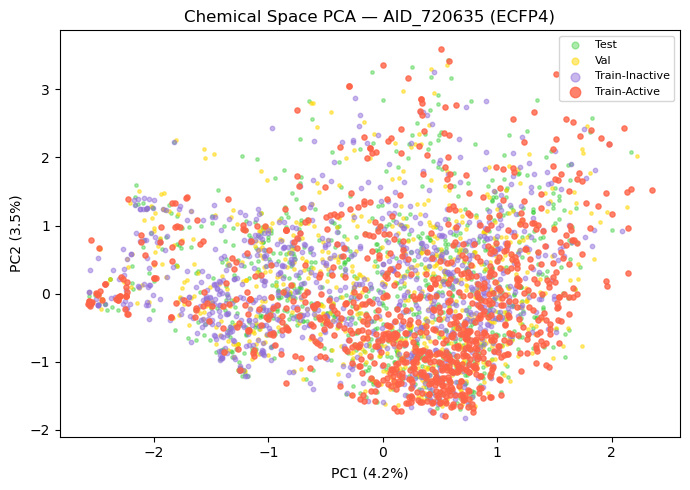

In [39]:
# ── 11. Split Summary & Chemical Space PCA ───────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={( ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_720635 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('chem_space.png',dpi=150); plt.show()


Left-out inactives : 1,152
PC1: 4.2%  PC2: 3.5%  PC3: 2.6%
Total variance explained: 10.3%


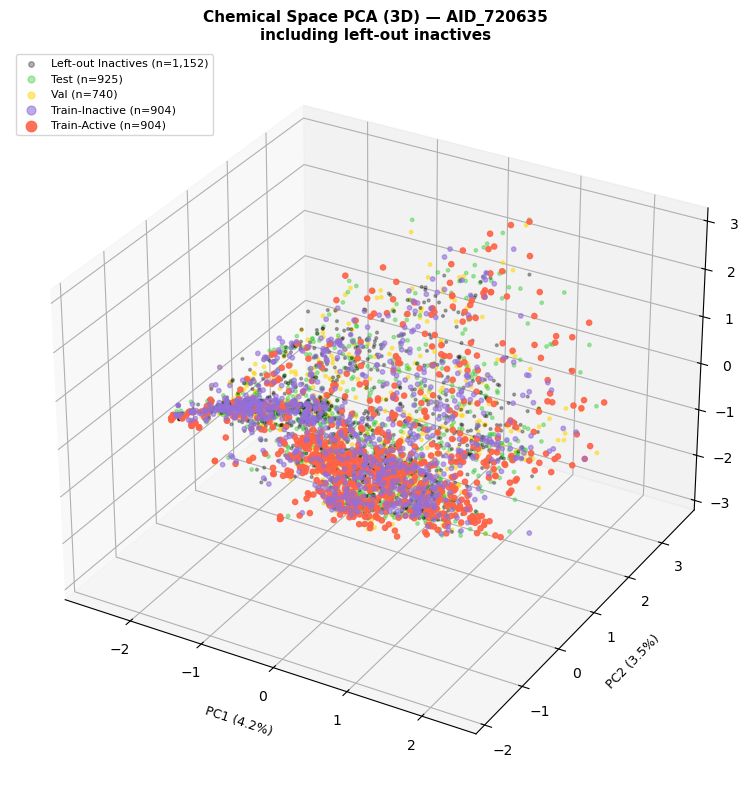

In [40]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) inactives ──────────────────────────────────
sampled_set     = set(sampled_ina.tolist())          # the 904 kept inactives
leftout_idx_tr  = np.array([idx for idx in ina_idx_tr 
                             if idx not in sampled_set])  # the 1,152 discarded
X_leftout       = X_tr_raw[leftout_idx_tr]           # their fingerprints

print(f'Left-out inactives : {len(leftout_idx_tr):,}')  # should be 1,152

# ── 3-component PCA ──────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)          # fit on balanced training set only

# Transform all sets including leftout
tr_3  = pca3.transform(X_train)    # (1808, 3) balanced train
va_3  = pca3.transform(X_val)      # ( 740, 3) val
te_3  = pca3.transform(X_test)     # ( 925, 3) test
lo_3  = pca3.transform(X_leftout)  # (1152, 3) discarded inactives

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100

print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

# ── 3D Plot ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

# Plot each group
ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
           c='black', s=4, alpha=0.3, label=f'Left-out Inactives (n={len(lo_3):,})')

ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')

ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')

ax.scatter(tr_3[y_train==0, 0], tr_3[y_train==0, 1], tr_3[y_train==0, 2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')

ax.scatter(tr_3[y_train==1, 0], tr_3[y_train==1, 1], tr_3[y_train==1, 2],
           c='tomato', s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

# Labels
ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — AID_720635\nincluding left-out inactives',
             fontsize=11, fontweight='bold')

ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_3d.png', dpi=150)
plt.show()


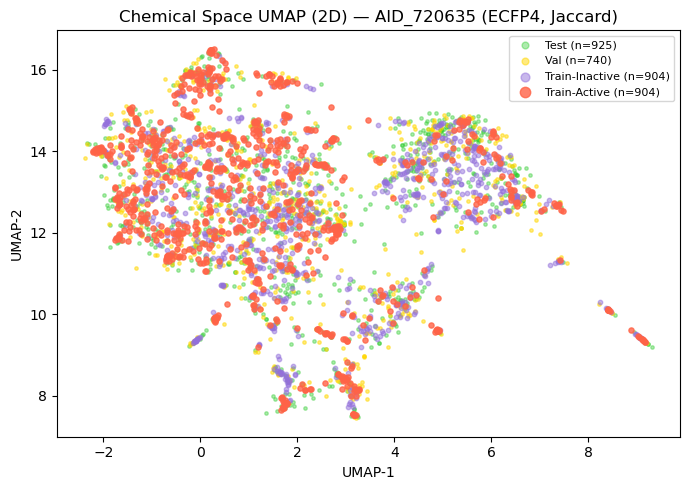

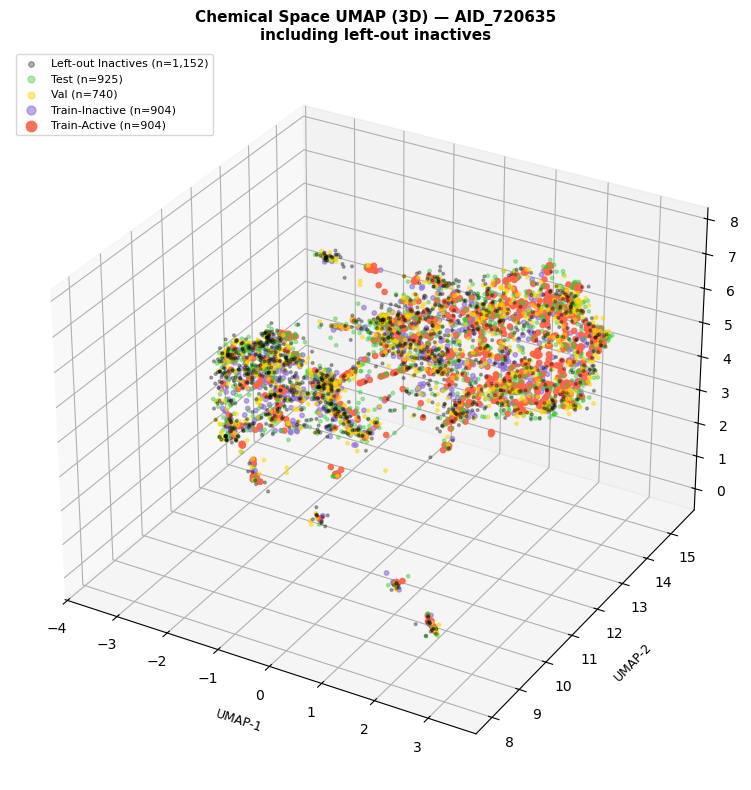

In [41]:
# ── 11b. Chemical Space UMAP ─────────────────────────────────────────────────
try:
    import umap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'umap-learn'])
    import umap

# ── 2D UMAP ──────────────────────────────────────────────────────────────────
reducer2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                     metric='jaccard', random_state=SEED)
reducer2.fit(X_train)

tr_u2 = reducer2.transform(X_train)
va_u2 = reducer2.transform(X_val)
te_u2 = reducer2.transform(X_test)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(te_u2[:, 0], te_u2[:, 1], c='limegreen',    s=6,  alpha=0.4, label=f'Test (n={len(te_u2):,})')
ax.scatter(va_u2[:, 0], va_u2[:, 1], c='gold',          s=6,  alpha=0.5, label=f'Val (n={len(va_u2):,})')
ax.scatter(tr_u2[y_train==0, 0], tr_u2[y_train==0, 1],
           c='mediumpurple', s=10, alpha=0.5, label=f'Train-Inactive (n={(y_train==0).sum():,})')
ax.scatter(tr_u2[y_train==1, 0], tr_u2[y_train==1, 1],
           c='tomato',       s=14, alpha=0.8, label=f'Train-Active (n={(y_train==1).sum():,})')
ax.set_xlabel('UMAP-1')
ax.set_ylabel('UMAP-2')
ax.set_title('Chemical Space UMAP (2D) — AID_720635 (ECFP4, Jaccard)')
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.savefig('chem_space_umap2d.png', dpi=150)
plt.show()

# ── 3D UMAP (including left-out inactives) ───────────────────────────────────
reducer3 = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1,
                     metric='jaccard', random_state=SEED)
reducer3.fit(X_train)

tr_u3 = reducer3.transform(X_train)
va_u3 = reducer3.transform(X_val)
te_u3 = reducer3.transform(X_test)
lo_u3 = reducer3.transform(X_leftout)

from mpl_toolkits.mplot3d import Axes3D   # noqa: F401 (registers 3d projection)

fig = plt.figure(figsize=(12, 8))
ax3 = fig.add_subplot(111, projection='3d')

ax3.scatter(lo_u3[:, 0], lo_u3[:, 1], lo_u3[:, 2],
            c='black',       s=4,  alpha=0.3, label=f'Left-out Inactives (n={len(lo_u3):,})')
ax3.scatter(te_u3[:, 0], te_u3[:, 1], te_u3[:, 2],
            c='limegreen',   s=6,  alpha=0.4, label=f'Test (n={len(te_u3):,})')
ax3.scatter(va_u3[:, 0], va_u3[:, 1], va_u3[:, 2],
            c='gold',        s=6,  alpha=0.5, label=f'Val (n={len(va_u3):,})')
ax3.scatter(tr_u3[y_train==0, 0], tr_u3[y_train==0, 1], tr_u3[y_train==0, 2],
            c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')
ax3.scatter(tr_u3[y_train==1, 0], tr_u3[y_train==1, 1], tr_u3[y_train==1, 2],
            c='tomato',       s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

ax3.set_xlabel('UMAP-1', fontsize=9, labelpad=8)
ax3.set_ylabel('UMAP-2', fontsize=9, labelpad=8)
ax3.set_zlabel('UMAP-3', fontsize=9, labelpad=8)
ax3.set_title('Chemical Space UMAP (3D) — AID_720635\nincluding left-out inactives',
              fontsize=11, fontweight='bold')
ax3.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_umap3d.png', dpi=150)
plt.show()


---
## Step 4 — Evaluation Helpers


In [42]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')


Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.


In [43]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'  : [300, 500],
    'max_features'  : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'     : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')


RF: 16 configs...
Best RF  val AUC=0.8661  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


In [44]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')


SVM: 9 configs...
Best SVM val AUC=0.8631  params={'C': 10, 'gamma': 0.01}


In [45]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')


XGB: 12 configs...
Best XGB val AUC=0.8665  params={'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}


In [46]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))


── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         79.2         77.8  78.5   0.8661  0.7759  0.5370   
              0.8         37.6         98.1  67.8   0.8661  0.7759  0.4911   
SVM           0.5         79.6         76.7  78.1   0.8631  0.7342  0.5281   
              0.8         50.4         94.0  72.2   0.8631  0.7342  0.5153   
XGBoost       0.5         80.1         77.4  78.8   0.8665  0.7577  0.5405   
              0.8         58.0         91.4  74.7   0.8665  0.7577  0.5355   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     78.5  0.6898  
              0.8     67.8  0.5296  
SVM           0.5     78.1  0.6844  
              0.8     72.2  0.6146  
XGBoost       0.5     78.8  0.6922  
              0.8     74.7  0.6534


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         81.9         80.2  81.1   0.8893  0.8192  0.5875   
              0.8         42.6         98.1  70.3   0.8893  0.8192  0.5355   
SVM           0.5         79.4         79.9  79.7   0.8763  0.7643  0.5626   
              0.8         55.3         94.4  74.9   0.8763  0.7643  0.5644   
XGBoost       0.5         81.2         81.2  81.2   0.8795  0.7805  0.5922   
              0.8         61.7         91.8  76.7   0.8795  0.7805  0.5719   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     81.1  0.7219  
              0.8     70.3  0.5797  
SVM           0.5     79.7  0.7055  
              0.8     74.9  0.6582  
XGBoost       0.5     81.2  0.7247  
              0.8     76.7  0.6837

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES  Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 × [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden→hidden/2→1]
  - BCEWithLogitsLoss
```
Tuned hyperparameters per architecture: `hidden`, `n_layers`, `dropout`, `lr`  
Selection criterion: **val ROC-AUC** | Early stopping patience=20 epochs


In [47]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
     GNN for molecular binary classification.
     GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        # Input projection
        self.proj = nn.Linear(in_dim, hidden) #linear layer to project input features to hidden dim
        self.bn0  = nn.BatchNorm1d(hidden) #batch norm after input projection

        # Conv layers + BatchNorm
        self.convs = nn.ModuleList() #list to hold convolutional layers
        self.bns   = nn.ModuleList() #list to hold batch norm layers after each conv
        for _ in range(n_layers): 
#             GCNConv(128, 128):
# Each atom collects messages from neighbours
# → takes weighted average
# → updates its own 128 numbers

            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                # concat=False → output stays at hidden dim
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        # MLP classification head
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden//2, 1)   # logit output for BCEWithLogitsLoss
        )

    def forward(self, x, edge_index, batch):
        # Input projection
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        # Conv layers with residual connections
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res          # skip connection (same dim)
        # Global readout + head
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)   # (B,)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')


MolGNN defined. ATOM_DIM=27


In [48]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')


Training helpers defined.


In [49]:
# ── 19. GNN DataLoaders ──────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

# Positive weight for BCEWithLogitsLoss — upweights active class in GNN training
# (training set is balanced 1:1, so pos_weight=1)
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs: {len(graphs_train)}')
print(f'Val   graphs: {len(graphs_val)}')
print(f'Test  graphs: {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')


Train graphs: 1808
Val   graphs: 740
Test  graphs: 925
pos_weight   : 1.000 (1.0 = balanced)


In [50]:
# ── 20. Hyperparameter Grid & Training Loop ──────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20   # early stopping

gnn_best_models  = {}   # best state_dict per architecture
gnn_best_configs = {}   # best hyperparams per architecture
gnn_best_val_auc = {}
gnn_history      = {}   # training curves

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads  # restore

        best_ep_auc, no_improv = 0, 0
        best_ep_state = None
        train_aucs, val_aucs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            loss = gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _,_, tr_auc = gnn_eval(model, train_loader, DEVICE)
            _,_, va_auc = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_auc)
            train_aucs.append(tr_auc); val_aucs.append(va_auc)
            if va_auc > best_ep_auc:
                best_ep_auc  = va_auc
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_auc > best_auc:
            best_auc   = best_ep_auc
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_aucs, val_aucs)

        cfg_str = {k:v for k,v in cfg.items()}
        print(f'  {cfg_str}  →  val AUC={best_ep_auc:.4f}  stopped@ep{len(train_aucs)}')

    gnn_best_val_auc[arch]  = best_auc
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: AUC={best_auc:.4f}  cfg={best_cfg}')



Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8869  stopped@ep100
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8891  stopped@ep93
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val AUC=0.8725  stopped@ep100
>> Best GCN: AUC=0.8891  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8768  stopped@ep56
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val AUC=0.8810  stopped@ep82
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8721  stopped@ep42
>> Best GAT: AUC=0.8810  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 

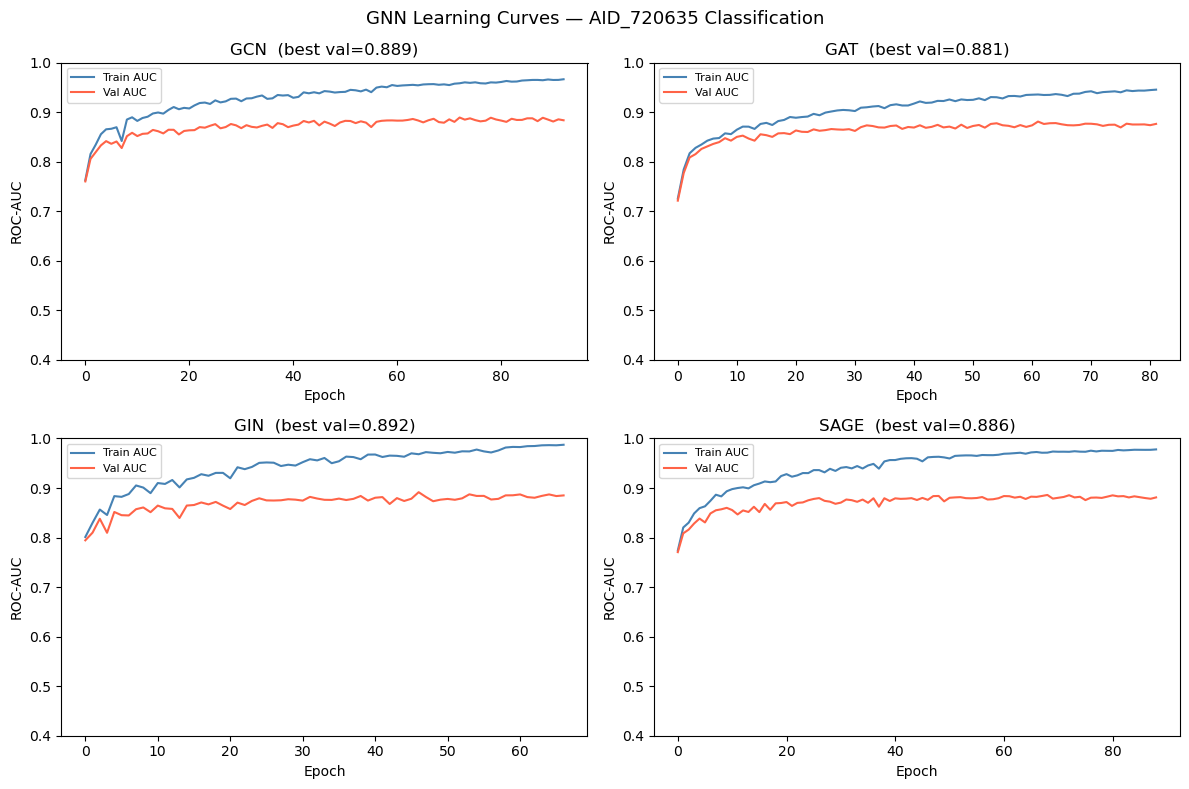

In [51]:
# ── 21. Learning Curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — AID_720635 Classification', fontsize=13)
plt.tight_layout(); plt.savefig('gnn_learning_curves.png',dpi=150); plt.show()


In [52]:
# ── 22. GNN Test Evaluation ──────────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))


── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         82.6         82.0  82.3   0.8924  0.7972  0.6134     82.3   
      0.8         66.3         93.8  80.0   0.8924  0.7972  0.6428     80.0   
GAT   0.5         83.7         81.2  82.4   0.8899  0.8019  0.6134     82.4   
      0.8         54.6         96.4  75.5   0.8899  0.8019  0.5972     75.5   
GIN   0.5         84.4         80.1  82.2   0.9005  0.8223  0.6071     82.2   
      0.8         69.1         91.9  80.5   0.9005  0.8223  0.6354     80.5   
SAGE  0.5         84.0         82.4  83.2   0.9001  0.8233  0.6309     83.2   
      0.8         73.8         92.1  82.9   0.9001  0.8233  0.6749     82.9   

               F1  
Model CPT          
GCN   0.5  0.7385  
      0.8  0.7348  
GAT   0.5  0.7387  
      0.8  0.6710  
GIN   0.5  0.7346  
      0.8  0.7372  
SAGE  0.5  0.7500  
      0.8  0.7689

---
## Step 7 — Consensus Model (All Classical + GNN)


In [53]:
# ── 23. Consensus: Average All Model Probabilities ───────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

# Classical-only consensus
cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

# GNN-only consensus
gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT'])) #to check if we can 3rd categoruy for inactive


── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         81.9         80.2  81.1   0.8893  0.8192   
                    0.8         42.6         98.1  70.3   0.8893  0.8192   
SVM                 0.5         79.4         79.9  79.7   0.8763  0.7643   
                    0.8         55.3         94.4  74.9   0.8763  0.7643   
XGBoost             0.5         81.2         81.2  81.2   0.8795  0.7805   
                    0.8         61.7         91.8  76.7   0.8795  0.7805   
GCN                 0.5         82.6         82.0  82.3   0.8924  0.7972   
                    0.8         66.3         93.8  80.0   0.8924  0.7972   
GAT                 0.5         83.7         81.2  82.4   0.8899  0.8019   
                    0.8         54.6         96.4  75.5   0.8899  0.8019   
GIN                 0.5         84.4         80.1  82.2   0.9005  0.8223   
                    0.8         69.1         91.9  80.5   0.9005  0.8223   
SAGE                0.5         84.0         82.4  83.2   0.9001  0.8233   
                    0.8         73.8         92.1  82.9   0.9001  0.8233   
Consensus           0.5         85.8         83.5  84.7   0.9147  0.8570   
                    0.8         56.4         97.5  76.9   0.9147  0.8570   
Consensus-Classical 0.5         81.9         81.8  81.9   0.8932  0.8197   
                    0.8         52.5         96.3  74.4   0.8932  0.8197   
Consensus-GNN       0.5         84.4         82.1  83.3   0.9073  0.8366   
                    0.8         65.6         95.3  80.5   0.9073  0.8366   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.5875     81.1  0.7219  
                    0.8  0.5355     70.3  0.5797  
SVM                 0.5  0.5626     79.7  0.7055  
                    0.8  0.5644     74.9  0.6582  
XGBoost             0.5  0.5922     81.2  0.7247  
                    0.8  0.5719     76.7  0.6837  
GCN                 0.5  0.6134     82.3  0.7385  
                    0.8  0.6428     80.0  0.7348  
GAT                 0.5  0.6134     82.4  0.7387  
                    0.8  0.5972     75.5  0.6710  
GIN                 0.5  0.6071     82.2  0.7346  
                    0.8  0.6354     80.5  0.7372  
SAGE                0.5  0.6309     83.2  0.7500  
                    0.8  0.6749     82.9  0.7689  
Consensus           0.5  0.6588     84.7  0.7683  
                    0.8  0.6335     76.9  0.6958  
Consensus-Classical 0.5  0.6055     81.9  0.7333  
                    0.8  0.5768     74.4  0.6520  
Consensus-GNN       0.5  0.6303     83.3  0.7496  
                    0.8  0.6641     80.5  0.7445

---
## Step 8 — Applicability Domain


AD threshold  : 0.6504
Test in AD    : 514/925 (55.6%)
  AD-filtered Sensitivity: 90.9
  AD-filtered Specificity: 84.8
  AD-filtered CCR: 87.9
  AD-filtered ROC-AUC: 0.9342
  AD-filtered MCC: 0.7417


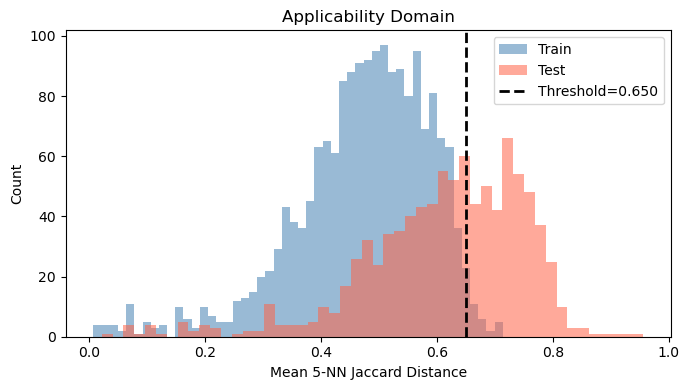

In [54]:
# ── 24. AD — k-NN Jaccard ────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain'); ax.legend()
plt.tight_layout(); plt.savefig('ad_dist.png',dpi=150); plt.show()


---
## Step 9 — Final Summary


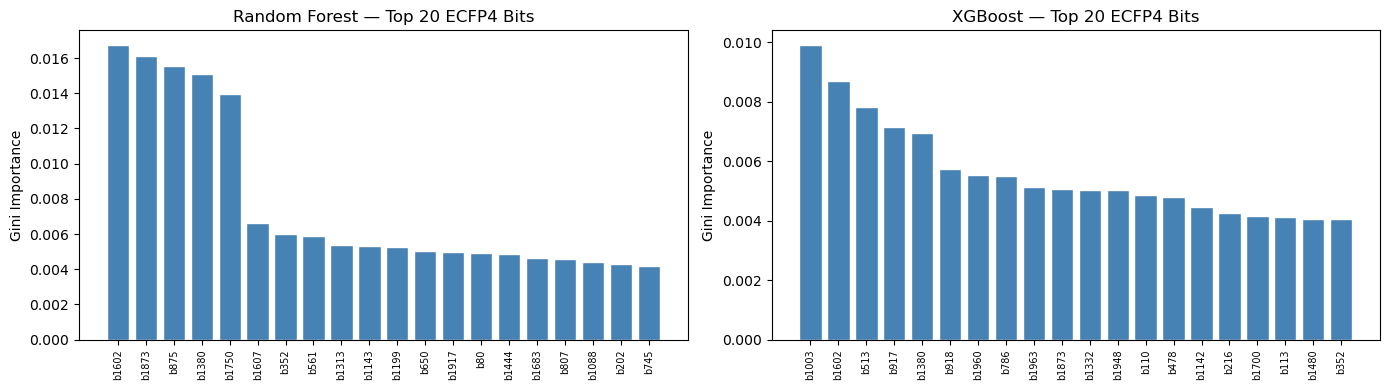

In [55]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('feat_importance.png',dpi=150); plt.show()


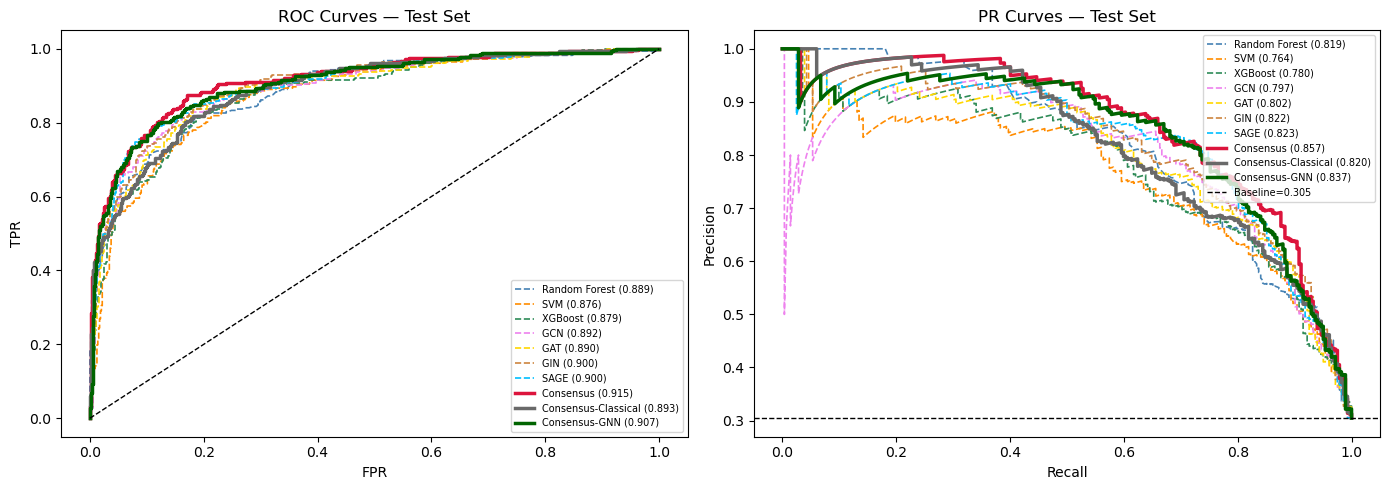

In [56]:
# ── 26. ROC Curves — All Models ──────────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('roc_pr_all.png',dpi=150); plt.show()


In [57]:
# ── 27. Ranked Summary Table (CPT-1) ─────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('═'*90)
print('FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)')
print('80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features')
print('═'*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('qsar_mito_final_results.csv')
print('Saved → qsar_mito_final_results.csv')


══════════════════════════════════════════════════════════════════════════════════════════
FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)
80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features
══════════════════════════════════════════════════════════════════════════════════════════


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Consensus,85.8,83.5,84.7,0.9147,0.8570,0.6588,84.7,0.7683
Consensus-GNN,84.4,82.1,83.3,0.9073,0.8366,0.6303,83.3,0.7496
GIN,84.4,80.1,82.2,0.9005,0.8223,0.6071,82.2,0.7346
SAGE,84.0,82.4,83.2,0.9001,0.8233,0.6309,83.2,0.7500
Consensus-Classical,81.9,81.8,81.9,0.8932,0.8197,0.6055,81.9,0.7333
GCN,82.6,82.0,82.3,0.8924,0.7972,0.6134,82.3,0.7385
GAT,83.7,81.2,82.4,0.8899,0.8019,0.6134,82.4,0.7387
Random Forest,81.9,80.2,81.1,0.8893,0.8192,0.5875,81.1,0.7219
XGBoost,81.2,81.2,81.2,0.8795,0.7805,0.5922,81.2,0.7247



Applicability Domain coverage: 55.6%
Saved → qsar_mito_final_results.csv


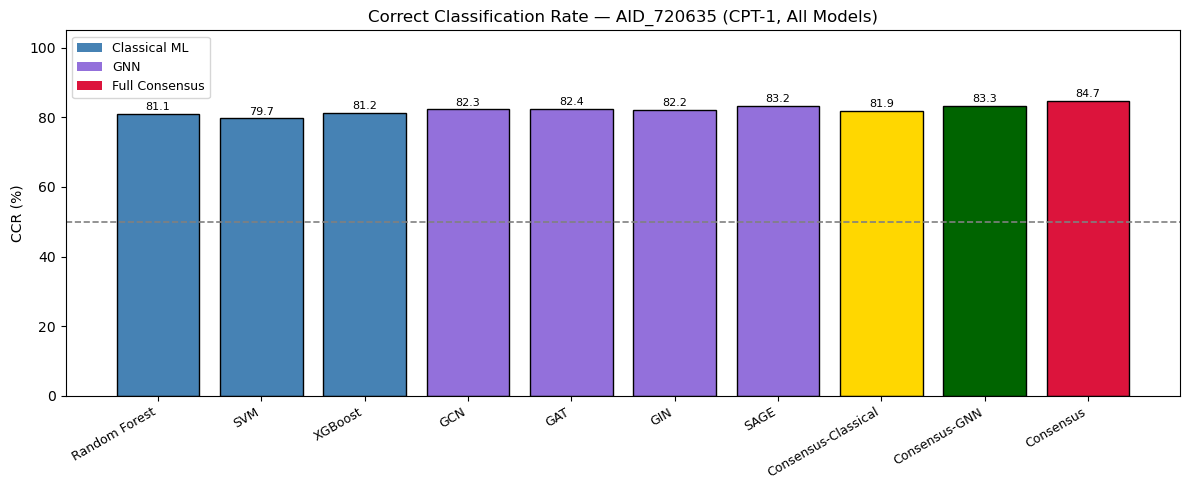

In [58]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — AID_720635 (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
ax.legend()
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('ccr_all_models.png',dpi=150); plt.show()


Best model (ROC-AUC): Consensus
              precision    recall  f1-score   support

 Inactive(0)       0.93      0.84      0.88       643
   Active(1)       0.70      0.86      0.77       282

    accuracy                           0.84       925
   macro avg       0.81      0.85      0.82       925
weighted avg       0.86      0.84      0.85       925



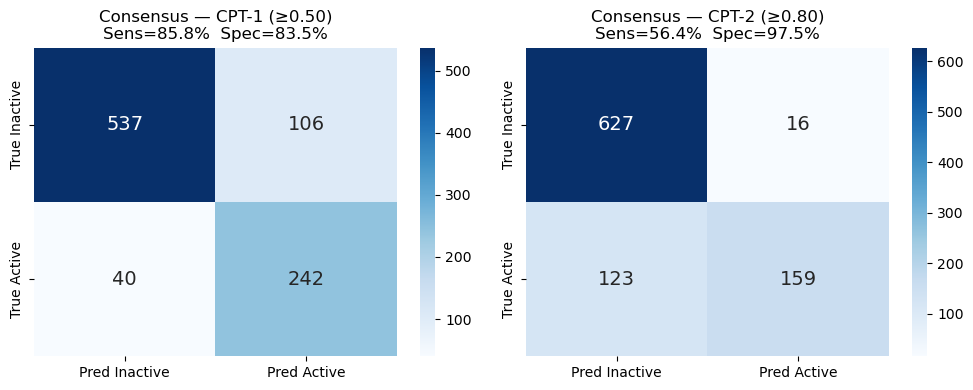

In [59]:
# ── 29. Best Model Report ─────────────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

# Confusion matrix
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('confusion_final.png',dpi=150); plt.show()


---
## Step 10 — Single Compound Prediction

Paste any SMILES below to run it through all 7 trained models and get a consensus toxicity prediction.


Compound : C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O
Canonical: O=C(c1ccccc1)c1ccccc1O
Mol. Weight: 198.22 Da  |  Atoms: 15

════════════════════════════════════════════════════════════
 INDIVIDUAL MODEL PROBABILITIES (P(Active))
════════════════════════════════════════════════════════════
  Model                   P(Active)    CPT-1    CPT-2
  -------------------------------------------------------
  Random Forest              0.9333   ACTIVE   ACTIVE  
  SVM                        0.8669   ACTIVE   ACTIVE  
  XGBoost                    0.9719   ACTIVE   ACTIVE  
  GCN                        0.9298   ACTIVE   ACTIVE  
  GAT                        0.8233   ACTIVE   ACTIVE  
  GIN                        0.9547   ACTIVE   ACTIVE  
  SAGE                       0.9721   ACTIVE   ACTIVE  
  Consensus-Classical        0.9240   ACTIVE   ACTIVE  
  Consensus-GNN              0.9200   ACTIVE   ACTIVE  
  CONSENSUS (all 7)          0.9217   ACTIVE   ACTIVE  ◄◄
══════════════════════════════════════════════

[08:33:50] DEPRECATION WARNING: please use MorganGenerator


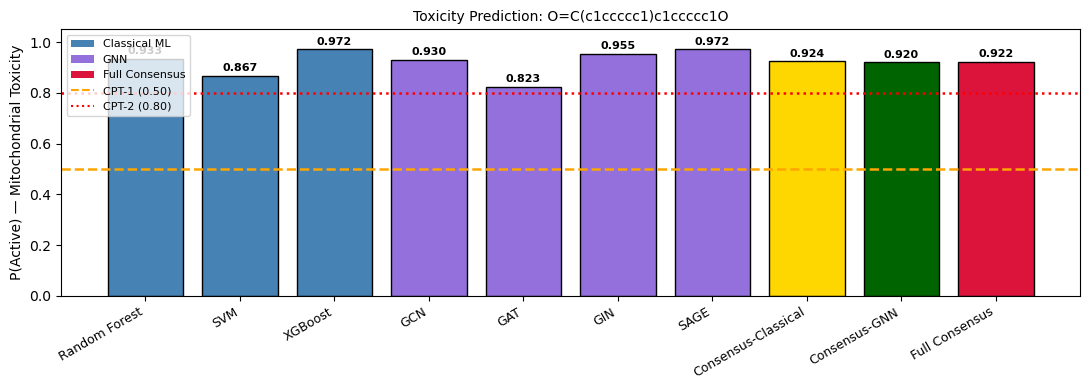

In [60]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# ► Change TEST_SMILES to any molecule you want to predict.
# ► Set TRUE_LABEL = 1 (Active) or 0 (Inactive) if you know it, else None.
# ─────────────────────────────────────────────────────────────────────────────

from rdkit.Chem import Descriptors   # needed for MolWt

TEST_SMILES  = "C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O"  
TRUE_LABEL   = None                       

# ── Step A: Parse & canonicalise ─────────────────────────────────────────────
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f"RDKit could not parse SMILES: {TEST_SMILES!r}  — check for typos.")

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f"Compound : {TEST_SMILES}")
print(f"Canonical: {canon}")
print(f"Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}")

# ── Step B: Morgan fingerprint (for classical ML + AD) ────────────────────────
fp_arr = smiles_to_ecfp4(canon)          # reuses function from Cell 5
X_query = fp_arr.reshape(1, -1)          # shape (1, 2048)

# ── Step C: Build graph (for GNN) ─────────────────────────────────────────────
graph_query = mol_to_graph(canon, label=0)   # label=0 is placeholder
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# ── Step D: Classical ML probabilities ────────────────────────────────────────
cl_query_probs = {}
for name, clf in classical.items():                # RF, SVM, XGBoost
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# ── Step E: GNN probabilities ─────────────────────────────────────────────────
gnn_query_probs = {}
for arch, state in gnn_best_models.items():        # GCN, GAT, GIN, SAGE
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).item())

# ── Step F: Consensus ─────────────────────────────────────────────────────────
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = float(np.mean(list(all_query_probs.values())))
cl_consensus_q  = float(np.mean(list(cl_query_probs.values())))
gnn_consensus_q = float(np.mean(list(gnn_query_probs.values())))

# ── Step G: Applicability Domain check ───────────────────────────────────────
d_query, _ = nn_ad.kneighbors(X_query)
md_query   = float(d_query.mean())
in_domain  = md_query <= ad_thr

# ── Step H: Pretty print ─────────────────────────────────────────────────────
print("\n" + "═"*60)
print(" INDIVIDUAL MODEL PROBABILITIES (P(Active))")
print("═"*60)
print(f"  {'Model':<22} {'P(Active)':>10}  {'CPT-1':>7}  {'CPT-2':>7}")
print("  " + "-"*55)
for name, p in {**all_query_probs,
                'Consensus-Classical': cl_consensus_q,
                'Consensus-GNN'      : gnn_consensus_q,
                'CONSENSUS (all 7)'  : consensus_q}.items():
    pred1 = "ACTIVE" if p >= 0.5 else "inactive"
    pred2 = "ACTIVE" if p >= 0.8 else "inactive"
    marker = "◄◄" if "CONSENSUS" in name else ""
    print(f"  {name:<22} {p:>10.4f}  {pred1:>7}  {pred2:>7}  {marker}")

print("═"*60)
print(f"\n  CONSENSUS PROBABILITY : {consensus_q:.4f}")

cpt1_call = "⚠  ACTIVE (Mitochondrially Toxic)" if consensus_q >= 0.5 else "✓  INACTIVE (Non-Toxic)"
cpt2_call = "⚠  ACTIVE (High-confidence)"        if consensus_q >= 0.8 else "✓  INACTIVE / uncertain"

print(f"  CPT-1 (≥0.50) verdict: {cpt1_call}")
print(f"  CPT-2 (≥0.80) verdict: {cpt2_call}")

ad_msg = f"INSIDE applicability domain  (dist={md_query:.4f} ≤ {ad_thr:.4f})" \
         if in_domain else \
         f"OUTSIDE applicability domain (dist={md_query:.4f} > {ad_thr:.4f}) — prediction may be unreliable"
print(f"\n  AD check   : {ad_msg}")

if TRUE_LABEL is not None:
    lbl_str = "Active (1)" if TRUE_LABEL == 1 else "Inactive (0)"
    correct = (consensus_q >= 0.5) == (TRUE_LABEL == 1)
    print(f"\n  True label : {lbl_str}  →  Prediction {'CORRECT ✓' if correct else 'WRONG ✗'}")

print("═"*60)

# ── Step I: Bar chart ─────────────────────────────────────────────────────────
plot_names  = list(all_query_probs.keys()) + ['Consensus-Classical','Consensus-GNN','Full Consensus']
plot_probs  = list(all_query_probs.values()) + [cl_consensus_q, gnn_consensus_q, consensus_q]
plot_colors = (['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(plot_names, plot_probs, color=plot_colors, edgecolor='black')
ax.axhline(0.5, color='orange', lw=1.8, ls='--', label='CPT-1 (0.50)')
ax.axhline(0.8, color='red',    lw=1.8, ls=':',  label='CPT-2 (0.80)')
for b, p in zip(bars, plot_probs):
    ax.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(Active) — Mitochondrial Toxicity')
ax.set_title(f'Toxicity Prediction: {canon}', fontsize=10)
ax.set_xticklabels(plot_names, rotation=30, ha='right', fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus'),
                   plt.Line2D([0],[0],color='orange',ls='--',label='CPT-1 (0.50)'),
                   plt.Line2D([0],[0],color='red',   ls=':' ,label='CPT-2 (0.80)')],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('single_compound_prediction.png', dpi=150)
plt.show()


---
## Step 11 — External Test Set: DILI In Vivo (DILIrank Gold Standard + LTKB-BD)

**DILIrank Gold Standard** (1,111 compounds) — curated clinical in vivo DILI labels.
**LTKB-BD** (FDA, AID 625276/277/278) — merged and deduplicated.

| Label | Meaning |
|---|---|
| `TOXICITY = 1` | DILI concern (hepatotoxic) |
| `TOXICITY = 0` | No DILI concern (safe) |

**Goal**: Test whether the AID_720635 mitotoxicity QSAR model (ECFP4 + GNN) translates to
in vivo DILI prediction — a genuinely independent external evaluation across a biological endpoint gap.

In [61]:
# ── E1. Load DILIrank Gold Standard + LTKB-BD & Assign Binary Labels ────────
# DILIrank Gold Standard
df_gold = pd.read_csv('../liver/DILI_Goldstandard_1111.csv')
print(f'DILIrank Gold Standard raw rows: {len(df_gold):,}')
print(df_gold['TOXICITY'].value_counts())

# LTKB-BD (AID 625276/277/278)
def load_ltkb(path, label, drop_not_applicable=False):
    df = pd.read_csv(path, skiprows=[1, 2])
    df = df.rename(columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles_r'})
    df = df[df['smiles_r'].notna() & (df['smiles_r'] != '')].copy()
    if drop_not_applicable and 'Activity Comment' in df.columns:
        mask = df['Activity Comment'].str.contains('not applicable', case=False, na=False)
        df = df[~mask]
    df['TOXICITY'] = label
    return df[['smiles_r', 'TOXICITY']]

df_ltkb76 = load_ltkb('../liver/AID_625276_datatable.csv', label=1, drop_not_applicable=True)
df_ltkb77 = load_ltkb('../liver/AID_625277_datatable.csv', label=1, drop_not_applicable=True)
df_ltkb78 = load_ltkb('../liver/AID_625278_datatable.csv', label=0)
df_ltkb = pd.concat([df_ltkb76, df_ltkb77, df_ltkb78], ignore_index=True)
print(f'LTKB-BD rows: {len(df_ltkb):,}')

# Merge: DILIrank + LTKB
df_gold_use = df_gold[['smiles_r', 'TOXICITY']].copy()
df_allDILI = pd.concat([df_gold_use, df_ltkb], ignore_index=True)

# Canonicalize SMILES, drop invalids, deduplicate
df_allDILI['csmi'] = df_allDILI['smiles_r'].apply(canonicalize)
df_allDILI = df_allDILI.dropna(subset=['csmi']).reset_index(drop=True)
df_allDILI = df_allDILI.drop_duplicates('csmi', keep='first').reset_index(drop=True)
df_allDILI['label'] = df_allDILI['TOXICITY'].astype(int)

pos = (df_allDILI['label'] == 1).sum()
neg = (df_allDILI['label'] == 0).sum()
print(f'\nDILI In Vivo External Test Set')
print(f'  Total compounds  : {len(df_allDILI):,}')
print(f'  DILI concern  (1): {pos:,}')
print(f'  No concern    (0): {neg:,}')
print(f'  Imbalance ratio  : {neg/pos:.2f}:1')


DILIrank Gold Standard raw rows: 1,111
TOXICITY
1    716
0    395
Name: count, dtype: int64
LTKB-BD rows: 218


[08:33:50] Explicit valence for atom # 4 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 1 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 15 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 15 P, 6, is greater than permitted



DILI In Vivo External Test Set
  Total compounds  : 1,217
  DILI concern  (1): 795
  No concern    (0): 422
  Imbalance ratio  : 0.53:1


[08:33:50] Explicit valence for atom # 14 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 6 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 1 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 21 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 3 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 5 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 3 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 7 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 11 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 11 P, 6, is greater than permitted
[08:33:50] Explicit valence for atom # 8 P, 6, is greater than permitted


In [62]:
# ── E2. Overlap Check: DILI In Vivo CIDs vs Mito Training Set ───────────────
mito_smis  = set(df['csmi'].dropna().tolist())   # full AID_720635 set (canonical SMILES)
dili_smis  = set(df_allDILI['csmi'].dropna().tolist())

overlap     = mito_smis & dili_smis
overlap_pct = 100 * len(overlap) / len(dili_smis) if dili_smis else 0

print(f'AID_720635 (mito) compounds   : {len(mito_smis):,}')
print(f'DILI In Vivo compounds        : {len(dili_smis):,}')
print(f'SMILES overlap                : {len(overlap):,}  ({overlap_pct:.1f}% of DILI set)')
print(f'Truly external (no overlap)   : {len(dili_smis)-len(overlap):,}  ({100-overlap_pct:.1f}%)')
print('(Even overlapping compounds are treated as external — different endpoint: DILI vs mitotoxicity)')


AID_720635 (mito) compounds   : 4,625
DILI In Vivo compounds        : 1,217
SMILES overlap                : 206  (16.9% of DILI set)
Truly external (no overlap)   : 1,011  (83.1%)
(Even overlapping compounds are treated as external — different endpoint: DILI vs mitotoxicity)


In [63]:
# ── E3. ECFP4 Fingerprints + Graphs for DILI In Vivo Compounds ───────────────
dili_fps_raw = df_allDILI['csmi'].apply(smiles_to_ecfp4)
valid_fp     = dili_fps_raw.notna()
df_dili_ext  = df_allDILI[valid_fp].reset_index(drop=True)
X_dili       = np.vstack(dili_fps_raw[valid_fp].values)
y_dili       = df_dili_ext['label'].values

# Build molecular graphs (same 27-dim atom features as mito training)
graphs_dili, valid_graph_idx_dili = [], []
for i, (smi, lbl) in enumerate(zip(df_dili_ext['csmi'].values, y_dili)):
    g = mol_to_graph(smi, lbl)
    if g is not None:
        graphs_dili.append(g)
        valid_graph_idx_dili.append(i)

valid_graph_idx_dili = np.array(valid_graph_idx_dili)
X_dili_gnn   = X_dili[valid_graph_idx_dili]
y_dili_gnn   = y_dili[valid_graph_idx_dili]
df_dili_gnn  = df_dili_ext.iloc[valid_graph_idx_dili].reset_index(drop=True)
dili_loader  = DataLoader(graphs_dili, batch_size=64, shuffle=False)

print(f'DILI fingerprint matrix : {X_dili.shape}')
print(f'Valid graphs            : {len(graphs_dili)} / {len(df_dili_ext)}')
print(f'FP density — DILI ext  : {X_dili.mean():.4f}  (train: {X_train.mean():.4f})')
print(f'DILI concern in GNN set : {(y_dili_gnn==1).sum()} / {len(y_dili_gnn)}')


[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerator
[08:33:50] DEPRECATION WARNING: please use MorganGenerat

DILI fingerprint matrix : (1217, 2048)
Valid graphs            : 1217 / 1217
FP density — DILI ext  : 0.0213  (train: 0.0150)
DILI concern in GNN set : 795 / 1217


AD threshold               : 0.6504
DILI compounds in AD       : 492/1217 (40.4%)
  DILI-concern (1) in AD   : 313 / 795
  No-concern   (0) in AD   : 179 / 422


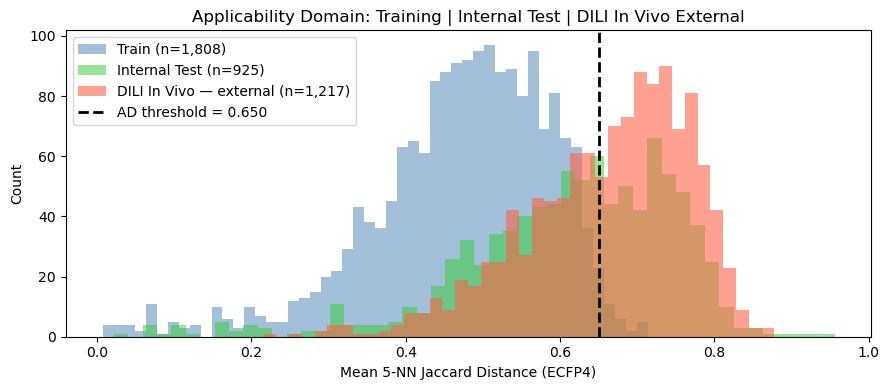

In [64]:
# ── E4. Applicability Domain — DILI In Vivo Compounds ────────────────────────
d_dili, _    = nn_ad.kneighbors(X_dili)
md_dili      = d_dili.mean(axis=1)
in_ad_dili   = md_dili <= ad_thr

print(f'AD threshold               : {ad_thr:.4f}')
print(f'DILI compounds in AD       : {in_ad_dili.sum()}/{len(y_dili)} ({in_ad_dili.mean()*100:.1f}%)')
print(f'  DILI-concern (1) in AD   : {(in_ad_dili & (y_dili==1)).sum()} / {(y_dili==1).sum()}')
print(f'  No-concern   (0) in AD   : {(in_ad_dili & (y_dili==0)).sum()} / {(y_dili==0).sum()}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(md_tr,   bins=50, alpha=0.5, color='steelblue', label=f'Train (n={len(md_tr):,})')
ax.hist(md_te,   bins=50, alpha=0.5, color='limegreen', label=f'Internal Test (n={len(md_te):,})')
ax.hist(md_dili, bins=40, alpha=0.6, color='tomato',    label=f'DILI In Vivo — external (n={len(md_dili):,})')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2, label=f'AD threshold = {ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance (ECFP4)')
ax.set_ylabel('Count')
ax.set_title('Applicability Domain: Training | Internal Test | DILI In Vivo External')
ax.legend(); plt.tight_layout()
plt.savefig('ad_dili_invivo_external.png', dpi=150); plt.show()


In [65]:
# ── E5. Classical ML — DILI In Vivo Evaluation ───────────────────────────────
cl_probs_dili = {n: clf.predict_proba(X_dili)[:,1] for n, clf in classical.items()}

rows_dili_cl = []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_dili_cl.append(evaluate(y_dili, cl_probs_dili[name], name, cpt))

df_dili_cl = pd.DataFrame(rows_dili_cl)[METRIC_COLS]
print('── Classical ML — DILI In Vivo External Test ──')
display(df_dili_cl.set_index(['Model','CPT']))


── Classical ML — DILI In Vivo External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         45.7         70.9  58.3   0.6037  0.7332  0.1605   
              0.8         10.1         96.4  53.3   0.6037  0.7332  0.1155   
SVM           0.5         44.2         67.3  55.7   0.5742  0.7071  0.1111   
              0.8         21.3         85.8  53.5   0.5742  0.7071  0.0857   
XGBoost       0.5         44.3         71.1  57.7   0.5911  0.7266  0.1500   
              0.8         24.7         84.1  54.4   0.5911  0.7266  0.1015   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     58.3  0.5667  
              0.8     53.3  0.1798  
SVM           0.5     55.7  0.5467  
              0.8     53.5  0.3301  
XGBoost       0.5     57.7  0.5548  
              0.8     54.4  0.3705

In [66]:
# ── E6. GNN — DILI In Vivo Evaluation ───────────────────────────────────────
gnn_probs_dili = {}
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    probs_g, _, _ = gnn_eval(model, dili_loader, DEVICE)
    gnn_probs_dili[arch] = probs_g

rows_dili_gnn = []
for arch, prob in gnn_probs_dili.items():
    for cpt in [0.5, 0.8]:
        rows_dili_gnn.append(evaluate(y_dili_gnn, prob, arch, cpt))

df_dili_gnn_res = pd.DataFrame(rows_dili_gnn)[METRIC_COLS]
print('── GNN — DILI In Vivo External Test ──')
display(df_dili_gnn_res.set_index(['Model','CPT']))


── GNN — DILI In Vivo External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         35.7         72.0  53.9   0.5735  0.7050  0.0785     53.9   
      0.8         17.6         90.3  53.9   0.5735  0.7050  0.1056     53.9   
GAT   0.5         38.7         70.9  54.8   0.5819  0.7165  0.0955     54.8   
      0.8         12.7         93.8  53.3   0.5819  0.7165  0.1019     53.3   
GIN   0.5         45.3         67.3  56.3   0.5897  0.7209  0.1218     56.3   
      0.8         25.0         83.2  54.1   0.5897  0.7209  0.0940     54.1   
SAGE  0.5         41.4         67.1  54.2   0.5796  0.7061  0.0826     54.2   
      0.8         21.9         84.8  53.4   0.5796  0.7061  0.0806     53.4   

               F1  
Model CPT          
GCN   0.5  0.4745  
      0.8  0.2869  
GAT   0.5  0.5024  
      0.8  0.2191  
GIN   0.5  0.5568  
      0.8  0.3737  
SAGE  0.5  0.5210  
      0.8  0.3369

In [67]:
# ── E7. Consensus — DILI In Vivo Full Summary ────────────────────────────────
# Use GNN-valid subset for all models to ensure consistent sample sizes
cl_probs_dili_gnn = {n: clf.predict_proba(X_dili_gnn)[:,1] for n, clf in classical.items()}
all_dili_probs    = {**cl_probs_dili_gnn, **gnn_probs_dili}

dili_consensus     = np.mean(list(all_dili_probs.values()), axis=0)
dili_cl_consensus  = np.mean(list(cl_probs_dili_gnn.values()), axis=0)
dili_gnn_consensus = np.mean(list(gnn_probs_dili.values()), axis=0)

all_dili_probs['Consensus']           = dili_consensus
all_dili_probs['Consensus-Classical'] = dili_cl_consensus
all_dili_probs['Consensus-GNN']       = dili_gnn_consensus

final_dili_rows = []
for name, prob in all_dili_probs.items():
    for cpt in [0.5, 0.8]:
        final_dili_rows.append(evaluate(y_dili_gnn, prob, name, cpt))

df_dili_final = pd.DataFrame(final_dili_rows)[METRIC_COLS]
summary_dili  = df_dili_final[df_dili_final['CPT'] == 0.5].set_index('Model').drop(columns='CPT')
summary_dili_sorted = summary_dili.sort_values('ROC-AUC', ascending=False)

print('='*90)
print('EXTERNAL TEST SET — DILI IN VIVO (DILIrank Gold Standard + LTKB-BD)')
print('Model trained on: AID_720635 (Mitochondrial Toxicity) | ECFP4 + GNN atom/bond features')
print('='*90)
display(summary_dili_sorted)
summary_dili_sorted.to_csv('dili_invivo_external_results.csv')
print('Saved → dili_invivo_external_results.csv')


EXTERNAL TEST SET — DILI IN VIVO (DILIrank Gold Standard + LTKB-BD)
Model trained on: AID_720635 (Mitochondrial Toxicity) | ECFP4 + GNN atom/bond features


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Random Forest,45.7,70.9,58.3,0.6037,0.7332,0.1605,58.3,0.5667
Consensus-Classical,44.5,71.6,58.0,0.5944,0.7273,0.1571,58.0,0.5579
Consensus,40.6,71.3,56.0,0.5913,0.7212,0.1182,56.0,0.5214
XGBoost,44.3,71.1,57.7,0.5911,0.7266,0.1500,57.7,0.5548
GIN,45.3,67.3,56.3,0.5897,0.7209,0.1218,56.3,0.5568
Consensus-GNN,40.5,70.6,55.6,0.5834,0.7151,0.1098,55.6,0.5189
GAT,38.7,70.9,54.8,0.5819,0.7165,0.0955,54.8,0.5024
SAGE,41.4,67.1,54.2,0.5796,0.7061,0.0826,54.2,0.5210
SVM,44.2,67.3,55.7,0.5742,0.7071,0.1111,55.7,0.5467


Saved → dili_invivo_external_results.csv


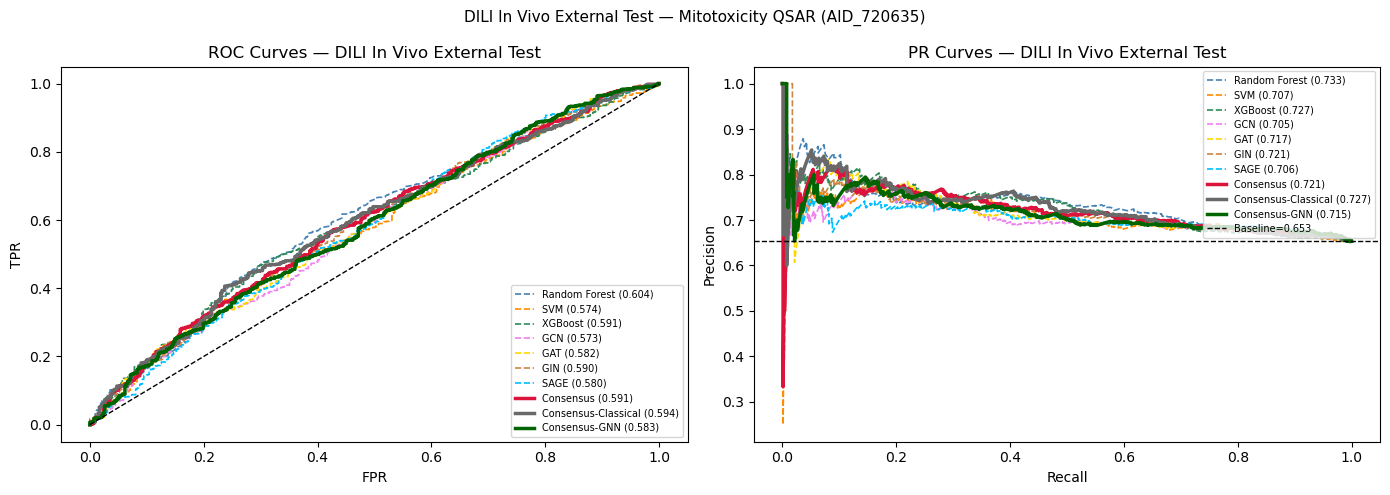

In [68]:
# ── E8. ROC / PR Curves — DILI In Vivo External Test ────────────────────────
COLORS_D = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
            'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
            'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in all_dili_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS_D.get(name, 'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr, tpr, _ = roc_curve(y_dili_gnn, prob)
    auc = roc_auc_score(y_dili_gnn, prob)
    axes[0].plot(fpr, tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre, rec, _ = precision_recall_curve(y_dili_gnn, prob)
    ap = average_precision_score(y_dili_gnn, prob)
    axes[1].plot(rec, pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — DILI In Vivo External Test')
axes[0].legend(fontsize=7, loc='lower right')

axes[1].axhline(y_dili_gnn.mean(), color='k', ls='--', lw=1,
                label=f'Baseline={y_dili_gnn.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — DILI In Vivo External Test')
axes[1].legend(fontsize=7, loc='upper right')

plt.suptitle('DILI In Vivo External Test — Mitotoxicity QSAR (AID_720635)', fontsize=11)
plt.tight_layout(); plt.savefig('roc_pr_dili_invivo_external.png', dpi=150); plt.show()


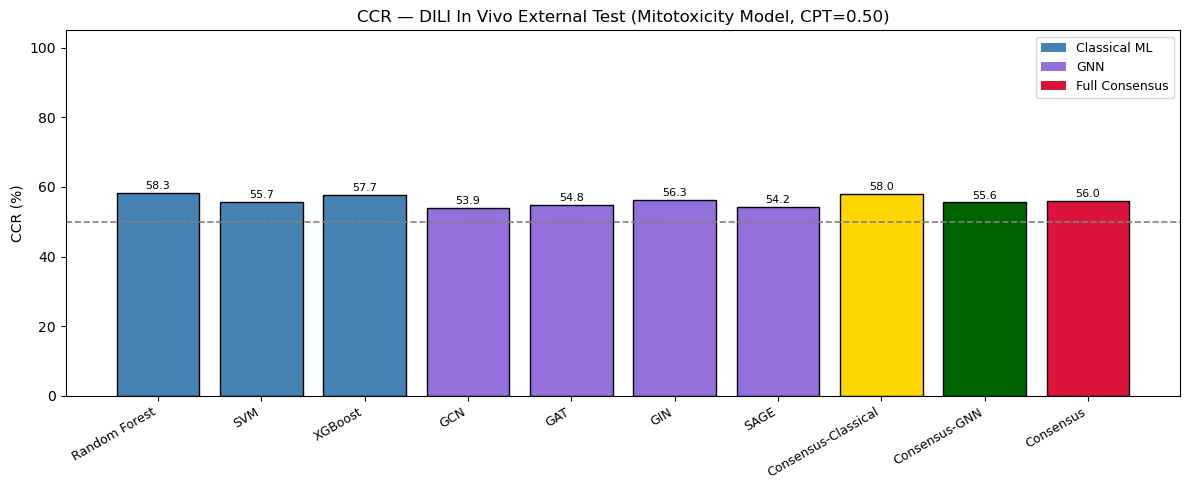


AD-filtered: 492 / 1217 DILI compounds inside AD (40.4%)
  Sensitivity  : 43.1%
  Specificity  : 74.9%
  CCR          : 59.0%
  ROC-AUC      : 0.6304
  MCC          : 0.1797


In [69]:
# ── E9. CCR Bar Chart + AD-Filtered Evaluation ───────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals   = [summary_dili.loc[m,'CCR'] if m in summary_dili.index else 0
              for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0, 105)
ax.set_title('CCR — DILI In Vivo External Test (Mitotoxicity Model, CPT=0.50)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue', label='Classical ML'),
                   Patch(facecolor='mediumpurple', label='GNN'),
                   Patch(facecolor='crimson', label='Full Consensus')], fontsize=9)
plt.tight_layout(); plt.savefig('ccr_dili_invivo_external.png', dpi=150); plt.show()

# AD-filtered evaluation
in_ad_dili_gnn = in_ad_dili[valid_graph_idx_dili]
n_in_ad = in_ad_dili_gnn.sum()
print(f'\nAD-filtered: {n_in_ad} / {len(y_dili_gnn)} DILI compounds inside AD ({n_in_ad/len(y_dili_gnn)*100:.1f}%)')
if n_in_ad >= 10:
    m_ad = evaluate(y_dili_gnn[in_ad_dili_gnn],
                    dili_consensus[in_ad_dili_gnn], 'Consensus (AD-filtered)')
    print(f'  Sensitivity  : {m_ad["Sensitivity"]}%')
    print(f'  Specificity  : {m_ad["Specificity"]}%')
    print(f'  CCR          : {m_ad["CCR"]}%')
    print(f'  ROC-AUC      : {m_ad["ROC-AUC"]}')
    print(f'  MCC          : {m_ad["MCC"]}')
else:
    print('  Too few AD-filtered compounds for meaningful evaluation.')


In [70]:
# ── E10. Comparison: Internal Test vs DILI In Vivo External Test ─────────────
internal_summary = df_final[df_final['CPT'] == 0.5].set_index('Model')
models_compare   = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE','Consensus']

comp_rows = []
for m in models_compare:
    if m in internal_summary.index and m in summary_dili.index:
        d_auc = round(internal_summary.loc[m,'ROC-AUC'] - summary_dili.loc[m,'ROC-AUC'], 4)
        comp_rows.append({
            'Model'                : m,
            'Internal ROC-AUC'     : internal_summary.loc[m, 'ROC-AUC'],
            'External ROC-AUC'     : summary_dili.loc[m, 'ROC-AUC'],
            'ΔAUC (drop)'          : d_auc,
            'Internal CCR'         : internal_summary.loc[m, 'CCR'],
            'External CCR'         : summary_dili.loc[m, 'CCR'],
            'Internal Sensitivity' : internal_summary.loc[m, 'Sensitivity'],
            'External Sensitivity' : summary_dili.loc[m, 'Sensitivity'],
            'Internal Specificity' : internal_summary.loc[m, 'Specificity'],
            'External Specificity' : summary_dili.loc[m, 'Specificity'],
        })

df_compare = pd.DataFrame(comp_rows).set_index('Model')
print('='*95)
print('COMPARISON TABLE: Internal Test (AID_720635 mitotoxicity) vs DILI In Vivo External')
print('='*95)
display(df_compare)
df_compare.to_csv('internal_vs_dili_invivo_comparison.csv')




COMPARISON TABLE: Internal Test (AID_720635 mitotoxicity) vs DILI In Vivo External


,Internal ROC-AUC,External ROC-AUC,ΔAUC (drop),Internal CCR,External CCR,Internal Sensitivity,External Sensitivity,Internal Specificity,External Specificity
Model,,,,,,,,,
Random Forest,0.8893,0.6037,0.2856,81.1,58.3,81.9,45.7,80.2,70.9
SVM,0.8763,0.5742,0.3021,79.7,55.7,79.4,44.2,79.9,67.3
XGBoost,0.8795,0.5911,0.2884,81.2,57.7,81.2,44.3,81.2,71.1
GCN,0.8924,0.5735,0.3189,82.3,53.9,82.6,35.7,82.0,72.0
GAT,0.8899,0.5819,0.3080,82.4,54.8,83.7,38.7,81.2,70.9
GIN,0.9005,0.5897,0.3108,82.2,56.3,84.4,45.3,80.1,67.3
SAGE,0.9001,0.5796,0.3205,83.2,54.2,84.0,41.4,82.4,67.1
Consensus,0.9147,0.5913,0.3234,84.7,56.0,85.8,40.6,83.5,71.3


---
## Step 12 — Figure 3B: IVIVC for Confirmed Toxicophores

**This is the in vitro → in vivo gap analysis (Kim et al. 2016 Figure 3B).**

For compounds containing each confirmed toxicophore fragment:
- **Left bar** — Experimental mito assay (AID 720635, *in vitro*) vs DILI liver damage (*in vivo*)
  — only possible for the **overlap compounds** tested in both
- **Right bar** — QSAR mito prediction vs DILI liver damage (*in vivo*)
  — possible for **all 1,111 DILI compounds** (QSAR fills the data gap)

The in vivo DILI label is the ground truth throughout.
A high CCR on the right bar means the mito QSAR can predict liver toxicity — closing the in vitro/in vivo gap.

Total DILI compounds with QSAR features : 1,217
Overlap (also in mito AID 720635)        : 206

Fetching fragment names from PubChem...
  c1ccc([N+](=O)[O-])cc1         -> c1ccc([N+](=O)[O-])cc1 (CID )
  c1ccc(Cl)cc1                   -> c1ccc(Cl)cc1 (CID )
  C=CC(=O)C                      -> C=CC(=O)C (CID )
  CCCCN(C)C                      -> CCCCN(C)C (CID )
  Oc1ccccc1                      -> Oc1ccccc1 (CID )
  O=C1C=CC(=O)C=C1               -> O=C1C=CC(=O)C=C1 (CID )
  CC=O                           -> CC=O (CID )
  C1OC1                          -> C1OC1 (CID )

Running substructure enrichment on DILI compounds...
  c1ccc([N+](=O)[O-])cc1       n=  32  enrich=1.39  p=0.0010  ***
  c1ccc(Cl)cc1                 n= 230  enrich=1.12  p=0.0036  **
  C=CC(=O)C                    n= 104  enrich=1.12  p=0.0498  *
  CCCCN(C)C                    n=  73  enrich=0.88  p=0.9401  ns
  Oc1ccccc1                    n= 144  enrich=0.91  p=0.9438  ns
  CC=O                         n=  10  enrich=0

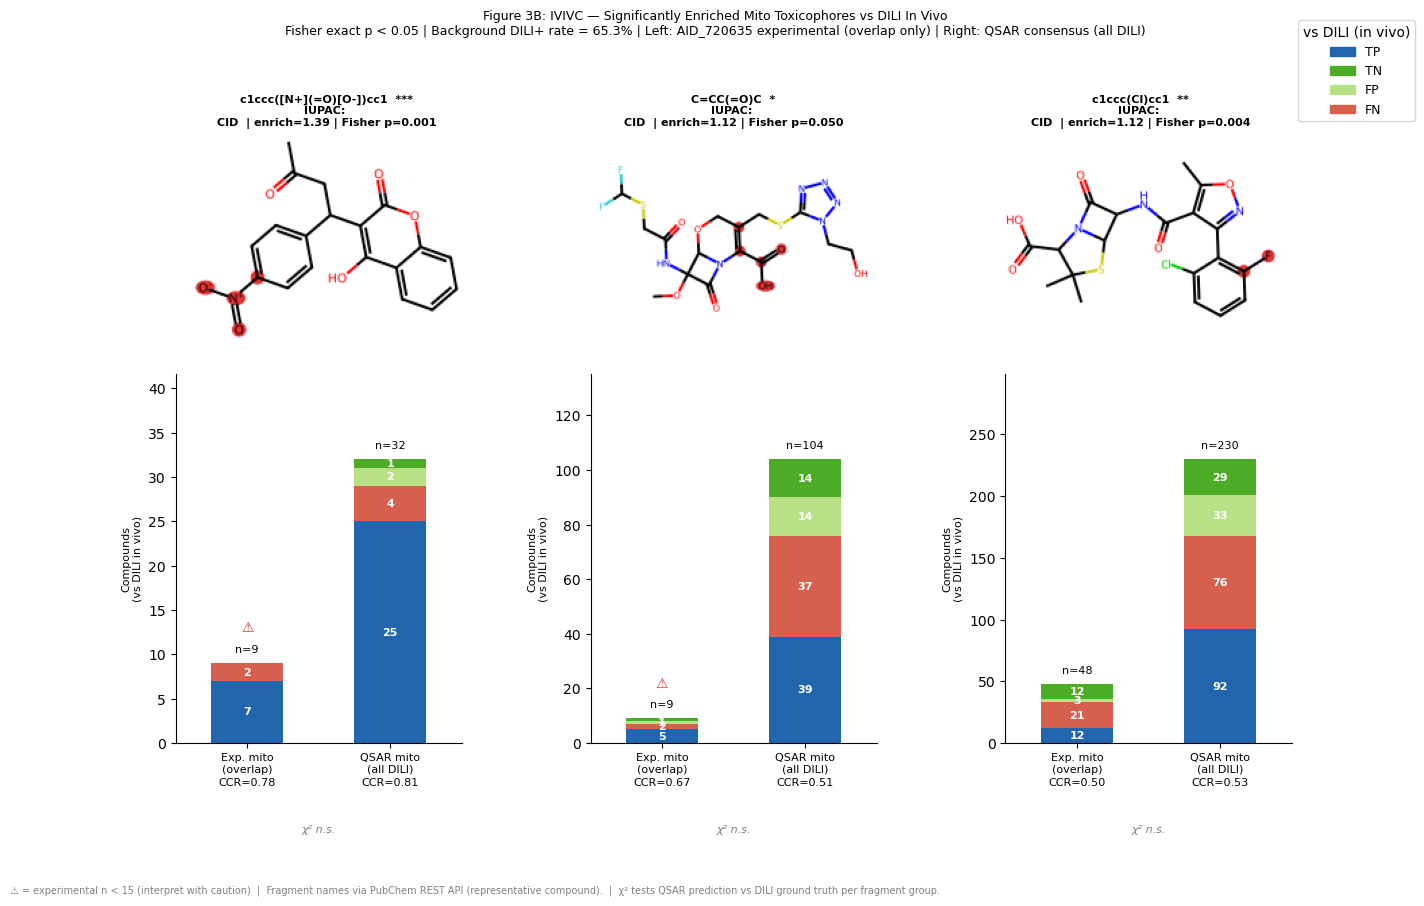

Saved => figure3b_ivivc_mito_dili.png


In [74]:
# -- E11. Figure 3B: IVIVC for Confirmed Toxicophores (Enriched Only) --------
# Ground truth  = DILI in vivo label (TOXICITY column)
# Predictor A   = experimental mito result (AID 720635, overlap compounds only)
# Predictor B   = QSAR mito consensus prediction (all DILI compounds)
# Fragment names = fetched from PubChem REST API via representative SMILES.
# Only fragments with Fisher exact p < 0.05 are shown.

import urllib.request, urllib.parse, time
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import rdMolDraw2D
from scipy.stats import chi2_contingency, fisher_exact
from PIL import Image
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

COLORS = {'TP': '#2166ac', 'TN': '#4dac26', 'FP': '#b8e186', 'FN': '#d6604d'}

# -- PubChem name lookup ------------------------------------------------------
def pubchem_name(smiles, fallback=''):
    """Return (Title, IUPACName, CID) for a SMILES via PubChem REST API."""
    url  = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/property/IUPACName,Title/JSON'
    data = urllib.parse.urlencode({'smiles': smiles}).encode()
    try:
        req = urllib.request.Request(url, data=data, method='POST')
        with urllib.request.urlopen(req, timeout=10) as r:
            props = json.loads(r.read())['PropertyTable']['Properties'][0]
        return props.get('Title', fallback), props.get('IUPACName', ''), props.get('CID', '')
    except Exception:
        return fallback, '', ''

# -- 1. Build overlap dataframe -----------------------------------------------
mito_lookup = df.set_index('csmi')['label'].to_dict()

df_dili_ext['qsar_pred']  = (dili_consensus >= 0.5).astype(int)
df_dili_ext['qsar_prob']  = dili_consensus
df_dili_ext['dili_label'] = y_dili
df_dili_ext['mito_exp']   = df_dili_ext['csmi'].map(mito_lookup)
df_dili_ext['in_overlap'] = df_dili_ext['mito_exp'].notna()

overlap_df = df_dili_ext[df_dili_ext['in_overlap']].copy()
overlap_df['mito_exp'] = overlap_df['mito_exp'].astype(int)

print(f'Total DILI compounds with QSAR features : {len(df_dili_ext):,}')
print(f'Overlap (also in mito AID 720635)        : {len(overlap_df):,}')

# -- 2. Define toxicophores + representative SMILES for PubChem lookup --------
# rep_smiles = simplest compound matching the SMARTS, used for PubChem name lookup
toxicophores = [
    {'smarts': '[c][N+](=O)[O-]',       'rep_smiles': 'c1ccc([N+](=O)[O-])cc1'},
    {'smarts': '[c][F,Cl,Br,I]',        'rep_smiles': 'c1ccc(Cl)cc1'},
    {'smarts': 'C=CC(=O)[#6,#7,#8]',   'rep_smiles': 'C=CC(=O)C'},
    {'smarts': '[N+;!$(NC=O)]',         'rep_smiles': 'CCCCN(C)C'},
    {'smarts': '[OH]c1ccccc1',          'rep_smiles': 'Oc1ccccc1'},
    {'smarts': 'O=C1C=CC(=O)C=C1',     'rep_smiles': 'O=C1C=CC(=O)C=C1'},
    {'smarts': '[CH1](=O)',             'rep_smiles': 'CC=O'},
    {'smarts': 'C1OC1',                 'rep_smiles': 'C1OC1'},
]

# Fetch PubChem names (one call per fragment, 0.3 s apart to respect rate limit)
print('\nFetching fragment names from PubChem...')
for tox in toxicophores:
    title, iupac, cid = pubchem_name(tox['rep_smiles'], fallback=tox['rep_smiles'])
    tox['name']  = title          # common/preferred name, e.g. "Nitrobenzene"
    tox['iupac'] = iupac          # IUPAC name, e.g. "nitrobenzene"
    tox['cid']   = cid
    print(f"  {tox['rep_smiles']:30s} -> {title} (CID {cid})")
    time.sleep(0.3)

def classify(true, pred):
    if   true==1 and pred==1: return 'TP'
    elif true==0 and pred==0: return 'TN'
    elif true==0 and pred==1: return 'FP'
    else:                     return 'FN'

def get_fragment_subsets(smarts, df_all, df_overlap):
    qmol = Chem.MolFromSmarts(smarts)
    if qmol is None: return None, None
    def has_match(smi):
        m = Chem.MolFromSmiles(str(smi))
        return bool(m) and m.HasSubstructMatch(qmol)
    mask_all = df_all['csmi'].apply(has_match)
    mask_ov  = df_overlap['csmi'].apply(has_match)
    return df_all[mask_all].copy(), df_overlap[mask_ov].copy()

# -- 3. Fisher enrichment — keep only p < 0.05 --------------------------------
print('\nRunning substructure enrichment on DILI compounds...')
bg_dili = df_dili_ext['dili_label'].mean()
enriched = []
for tox in toxicophores:
    df_hit, _ = get_fragment_subsets(tox['smarts'], df_dili_ext, overlap_df)
    if df_hit is None or len(df_hit) < 5: continue
    act      = df_hit['dili_label'].sum()
    inact    = len(df_hit) - act
    ratio    = (act / len(df_hit)) / (bg_dili + 1e-8)
    bg_act   = df_dili_ext['dili_label'].sum() - act
    bg_inact = len(df_dili_ext) - len(df_hit) - bg_act
    _, pval  = fisher_exact([[act, inact], [bg_act, bg_inact]], alternative='greater')
    sig = '***' if pval < 0.001 else ('**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns'))
    enriched.append({**tox, 'n': len(df_hit), 'n_act': int(act),
                     'enrichment': ratio, 'pval': pval, 'sig': sig})
    print(f"  {tox['name']:28s} n={len(df_hit):4d}  enrich={ratio:.2f}  p={pval:.4f}  {sig}")

enriched_df  = pd.DataFrame(enriched).sort_values('enrichment', ascending=False)
sig_enriched = enriched_df[enriched_df['pval'] < 0.05].reset_index(drop=True)
print(f'\nSignificantly enriched (Fisher p < 0.05): {len(sig_enriched)}')
for _, row in sig_enriched.iterrows():
    print(f"  {row['name']:28s} enrich={row['enrichment']:.2f}  {row['sig']}  "
          f"IUPAC: {row['iupac']}")

top_tox = []
for _, row in sig_enriched.iterrows():
    _, ov_hit = get_fragment_subsets(row['smarts'], df_dili_ext, overlap_df)
    if ov_hit is not None and len(ov_hit) >= 3:
        top_tox.append(dict(row))

if not top_tox:
    print('WARNING: no significantly enriched fragments with enough overlap compounds.')
else:
    print(f'Building Figure 3B for {len(top_tox)} toxicophores.')

# -- 4. Build Figure 3B -------------------------------------------------------
n_tox = len(top_tox)
fig   = plt.figure(figsize=(4.8 * n_tox, 9))
gs_mol = gridspec.GridSpec(1, n_tox, figure=fig, top=0.86, bottom=0.62,
                            hspace=0, wspace=0.35)
gs_bar = gridspec.GridSpec(1, n_tox, figure=fig, top=0.59, bottom=0.18,
                            hspace=0, wspace=0.45)

for col_i, tox in enumerate(top_tox):
    smarts    = tox['smarts']
    pub_name  = tox['name']          # PubChem common name
    iupac     = tox['iupac']         # IUPAC name
    cid       = tox['cid']
    sig       = tox['sig']
    df_all_hit, df_ov_hit = get_fragment_subsets(smarts, df_dili_ext, overlap_df)

    # Experimental bar
    df_ov_hit['cls_exp'] = df_ov_hit.apply(
        lambda r: classify(r['dili_label'], r['mito_exp']), axis=1)
    exp_counts = df_ov_hit['cls_exp'].value_counts()
    e_tp = int(exp_counts.get('TP',0)); e_tn = int(exp_counts.get('TN',0))
    e_fp = int(exp_counts.get('FP',0)); e_fn = int(exp_counts.get('FN',0))
    n_exp  = e_tp + e_tn + e_fp + e_fn
    ccr_exp = (e_tp + e_tn) / n_exp if n_exp > 0 else 0

    # QSAR bar
    df_all_hit['cls_qsar'] = df_all_hit.apply(
        lambda r: classify(r['dili_label'], r['qsar_pred']), axis=1)
    qsar_counts = df_all_hit['cls_qsar'].value_counts()
    q_tp = int(qsar_counts.get('TP',0)); q_tn = int(qsar_counts.get('TN',0))
    q_fp = int(qsar_counts.get('FP',0)); q_fn = int(qsar_counts.get('FN',0))
    n_qsar   = q_tp + q_tn + q_fp + q_fn
    ccr_qsar = (q_tp + q_tn) / n_qsar if n_qsar > 0 else 0

    # Chi-squared
    ct = np.array([[q_tp, q_fn], [q_fp, q_tn]])
    try:    _, pval_q, _, _ = chi2_contingency(ct, correction=False)
    except: pval_q = 1.0
    sig_q = '***' if pval_q < 0.001 else ('**' if pval_q < 0.01 else
            ('*'   if pval_q < 0.05  else 'n.s.'))

    # -- Molecule panel -------------------------------------------------------
    ax_mol = fig.add_subplot(gs_mol[0, col_i])
    qmol   = Chem.MolFromSmarts(smarts)
    drawn  = False
    for smi in df_all_hit['csmi'].head(20):
        mol = Chem.MolFromSmiles(str(smi))
        if mol and mol.HasSubstructMatch(qmol):
            match = list(mol.GetSubstructMatch(qmol))
            try:
                drawer = rdMolDraw2D.MolDraw2DCairo(220, 160)
                drawer.drawOptions().addAtomIndices = False
                rdMolDraw2D.PrepareAndDrawMolecule(
                    drawer, mol,
                    highlightAtoms=match,
                    highlightAtomColors={a: (0.9, 0.2, 0.2) for a in match}
                )
                drawer.FinishDrawing()
                ax_mol.imshow(Image.open(BytesIO(drawer.GetDrawingText())))
                drawn = True
                break
            except Exception:
                continue
    if not drawn:
        ax_mol.text(0.5, 0.5, pub_name, ha='center', va='center',
                    transform=ax_mol.transAxes, fontsize=9)
    ax_mol.axis('off')
    # Panel title: PubChem common name + IUPAC + Fisher significance
    ax_mol.set_title(
        f'{pub_name}  {sig}\n'
        f'IUPAC: {iupac}\n'
        f'CID {cid} | enrich={tox["enrichment"]:.2f} | Fisher p={tox["pval"]:.3f}',
        fontsize=8, fontweight='bold', pad=4
    )

    # -- Bar panel ------------------------------------------------------------
    ax_bar = fig.add_subplot(gs_bar[0, col_i])
    w     = 0.5
    max_n = max(n_exp, n_qsar, 1)

    for x_pos, (tp, tn, fp, fn, n) in enumerate([
        (e_tp, e_tn, e_fp, e_fn, n_exp),
        (q_tp, q_tn, q_fp, q_fn, n_qsar)
    ]):
        ax_bar.bar(x_pos, tp,          w, color=COLORS['TP'])
        ax_bar.bar(x_pos, fn, w, bottom=tp,          color=COLORS['FN'])
        ax_bar.bar(x_pos, fp, w, bottom=tp+fn,        color=COLORS['FP'])
        ax_bar.bar(x_pos, tn, w, bottom=tp+fn+fp,     color=COLORS['TN'])
        for val, bot in [(tp,0),(fn,tp),(fp,tp+fn),(tn,tp+fn+fp)]:
            if val > 0:
                ax_bar.text(x_pos, bot + val/2, str(val),
                            ha='center', va='center', fontsize=8,
                            color='white', fontweight='bold')
        # n count above bar
        ax_bar.text(x_pos, n + max_n * 0.03, f'n={n}',
                    ha='center', va='bottom', fontsize=8, color='black')
        # small-n warning above the count
        if n < 15:
            ax_bar.text(x_pos, n + max_n * 0.10, '⚠',
                        ha='center', va='bottom', fontsize=10, color='#d62728')

    # Simple x-tick labels — no n counts, no multi-line clutter
    ax_bar.set_xticks([0, 1])
    ax_bar.set_xticklabels(['Exp. mito\n(overlap)', 'QSAR mito\n(all DILI)'],
                            fontsize=8)
    ax_bar.set_ylabel('Compounds\n(vs DILI in vivo)', fontsize=8)
    ax_bar.set_ylim(0, max_n * 1.30)
    ax_bar.set_xlim(-0.5, 1.5)
    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)

    # CCR below x-axis
    dy = max_n * 0.15
    ax_bar.text(0,   -dy, f'CCR={ccr_exp:.2f}',  ha='center', fontsize=8)
    ax_bar.text(1,   -dy, f'CCR={ccr_qsar:.2f}', ha='center', fontsize=8)
    # Chi-squared: grey for n.s., red for significant
    chi_color = '#d62728' if pval_q < 0.05 else 'gray'
    ax_bar.text(0.5, -dy * 2.1, f'χ² {sig_q}', ha='center', fontsize=8,
                color=chi_color, style='italic')

    print(f"  {pub_name}: exp n={n_exp} CCR={ccr_exp:.2f} | "
          f"qsar n={n_qsar} CCR={ccr_qsar:.2f} chi2 {sig_q}")

# -- Legend + suptitle --------------------------------------------------------
handles = [mpatches.Patch(color=COLORS[k], label=k) for k in ['TP','TN','FP','FN']]
fig.legend(handles=handles, loc='upper right', fontsize=9,
           title='vs DILI (in vivo)', bbox_to_anchor=(0.99, 0.99))

fig.text(
    0.01, 0.01,
    '⚠ = experimental n < 15 (interpret with caution)  |  '
    'Fragment names via PubChem REST API (representative compound).  |  '
    'χ² tests QSAR prediction vs DILI ground truth per fragment group.',
    fontsize=7, color='gray', va='bottom'
)

fig.suptitle(
    'Figure 3B: IVIVC — Significantly Enriched Mito Toxicophores vs DILI In Vivo\n'
    f'Fisher exact p < 0.05 | Background DILI+ rate = {bg_dili*100:.1f}% | '
    'Left: AID_720635 experimental (overlap only) | Right: QSAR consensus (all DILI)',
    fontsize=9, y=0.995
)

plt.savefig('figure3b_ivivc_mito_dili.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved => figure3b_ivivc_mito_dili.png')
